# Placement probe: does single-operation behaviour depend on the slot position?

**Inference only.** This notebook loads the already-selected checkpoints (`runs/<model>/best.pt`) of the
mixed-length experiments (notebooks 04 and 05). It does not train, fine-tune or re-select anything, and it uses no
optimizer. AR models decode free-running.

**Motivation.** In the standard test, a single operation is encoded as `[X, PAD, PAD, PAD, PAD]`. Several models
output "X then C" (A→AC, B→BC, C→CC = identity) on it. This probe asks whether that behaviour depends on where the
operation sits:

* **Singles:** A, B and C, each placed in slot 1, 2, 3, 4 and 5 (all other slots PAD), on the 1000 test base grids.
* **Control:** the experiment's trained length-two pairs in all 10 order-preserving placements (all of which occur
  in training), on 200 grids. This shows whether non-canonical placements are handled correctly for a TRAINED
  length.

Each prediction is checked against the truth and against explicit candidate rules: "X then C", "X twice", identity,
and every original training pair. It is also checked against all 288 legal transformations (the dominant wrong one
is reported). Results are behavioural, from one seed, and non-causal.


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: bc176e2089c41f3343c5a906e0214eb95ccaea64


In [2]:
# --- CONFIGURATION ---------------------------------------------------------------------------------------
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
MIXED_ROOT = os.environ.get("DECOMP_MIXED_ROOT") or f"{RESULTS_ROOT}/mixed_length_02345"
EXPERIMENTS = ["mixed_02345_distinct_pairs", "mixed_02345_all_pairs"]
MODELS = os.environ.get("DECOMP_MODELS", "transformer_ar,looped_transformer_ar,transformer_encoder,"
                        "looped_transformer_encoder,vit,looped_vit,trm,rescnn_film,unet_film").split(",")
N_SINGLE_GRIDS = int(os.environ.get("DECOMP_PROBE_GRIDS", 1000))   # singles: 3 ops x 5 slots x grids
N_PAIR_GRIDS = int(os.environ.get("DECOMP_PROBE_PAIR_GRIDS", 200))  # control: pairs x 10 placements x grids
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
DTYPE = "auto"
OUTPUT_DIR = f"{MIXED_ROOT}/placement_probe"
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
print("reading checkpoints from:", MIXED_ROOT)
print("writing probe outputs to:", OUTPUT_DIR)


Mounted at /content/drive
reading checkpoints from: /content/drive/MyDrive/decompositionality_results/mixed_length_02345
writing probe outputs to: /content/drive/MyDrive/decompositionality_results/mixed_length_02345/placement_probe


[mixed_02345_distinct_pairs/transformer_ar] probed 27,000 records (selected step 5000) in 24s
[mixed_02345_distinct_pairs/looped_transformer_ar] probed 27,000 records (selected step 5000) in 21s
[mixed_02345_distinct_pairs/transformer_encoder] probed 27,000 records (selected step 4750) in 5s
[mixed_02345_distinct_pairs/looped_transformer_encoder] probed 27,000 records (selected step 5000) in 2s
[mixed_02345_distinct_pairs/vit] probed 27,000 records (selected step 5000) in 5s
[mixed_02345_distinct_pairs/looped_vit] probed 27,000 records (selected step 5000) in 2s
[mixed_02345_distinct_pairs/trm] probed 27,000 records (selected step 5000) in 8s
[mixed_02345_distinct_pairs/rescnn_film] probed 27,000 records (selected step 5000) in 6s
[mixed_02345_distinct_pairs/unet_film] probed 27,000 records (selected step 5000) in 4s
[mixed_02345_all_pairs/transformer_ar] probed 33,000 records (selected step 4750) in 27s
[mixed_02345_all_pairs/looped_transformer_ar] probed 33,000 records (selected step

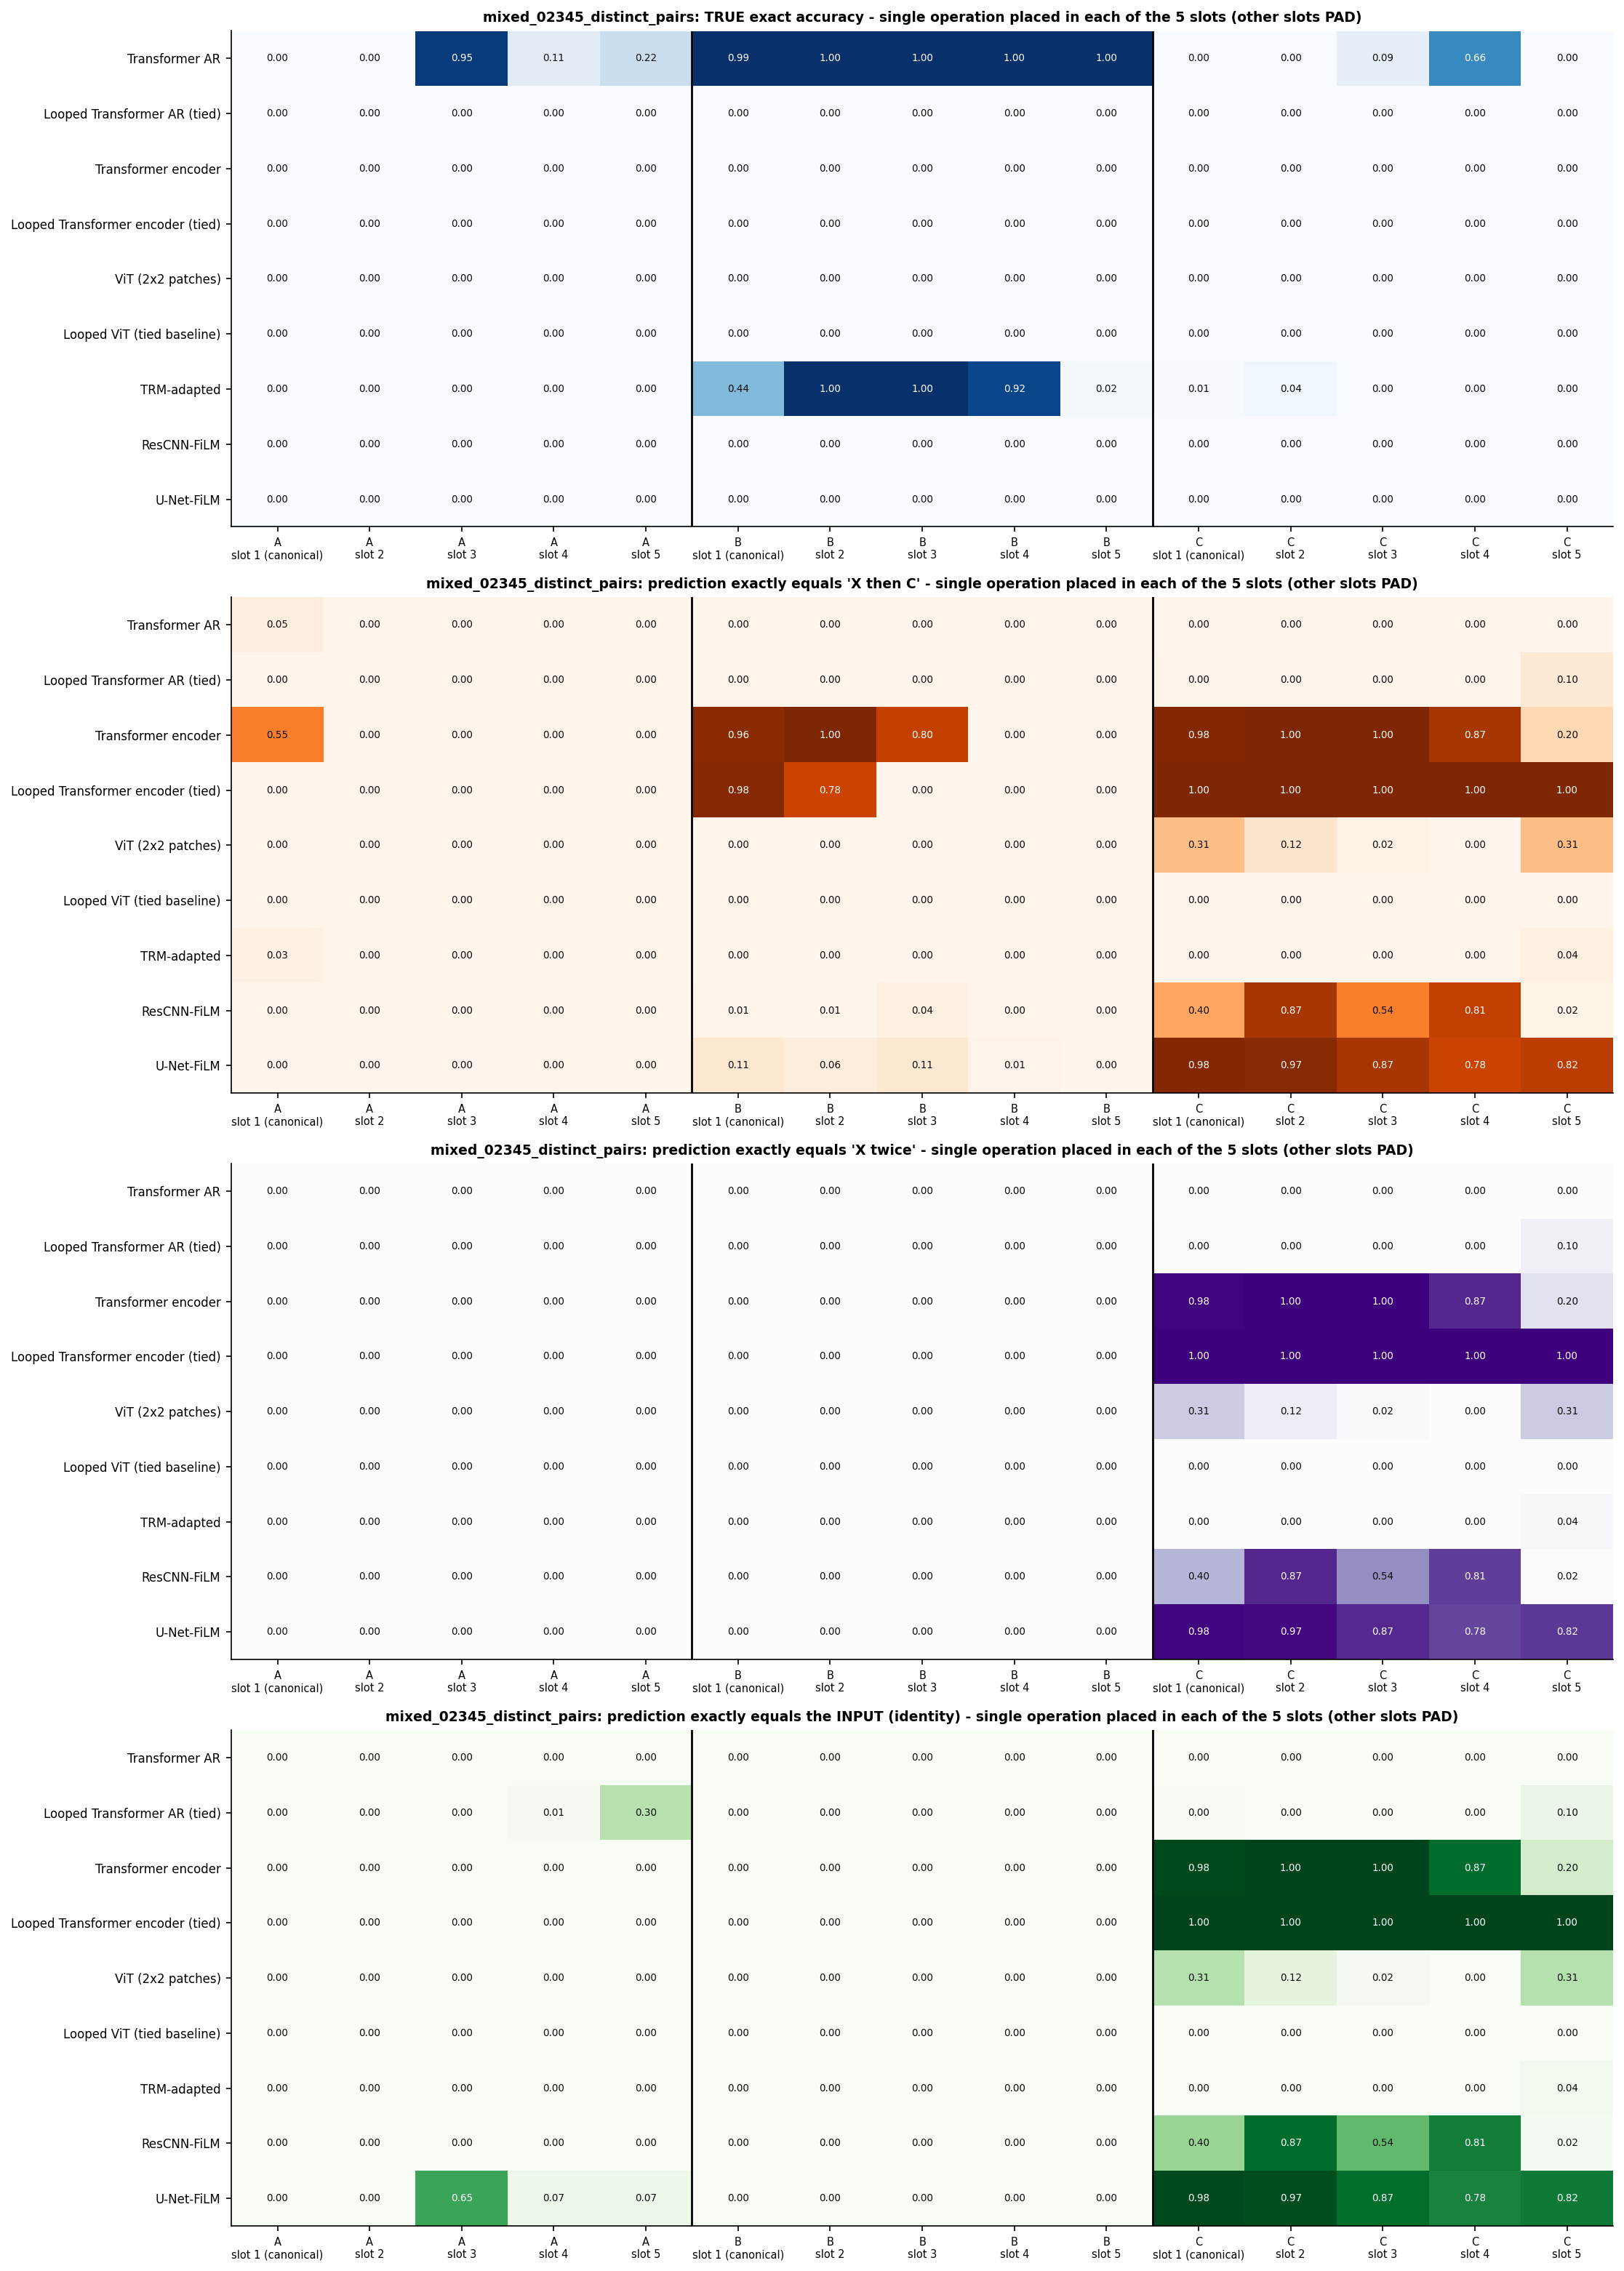

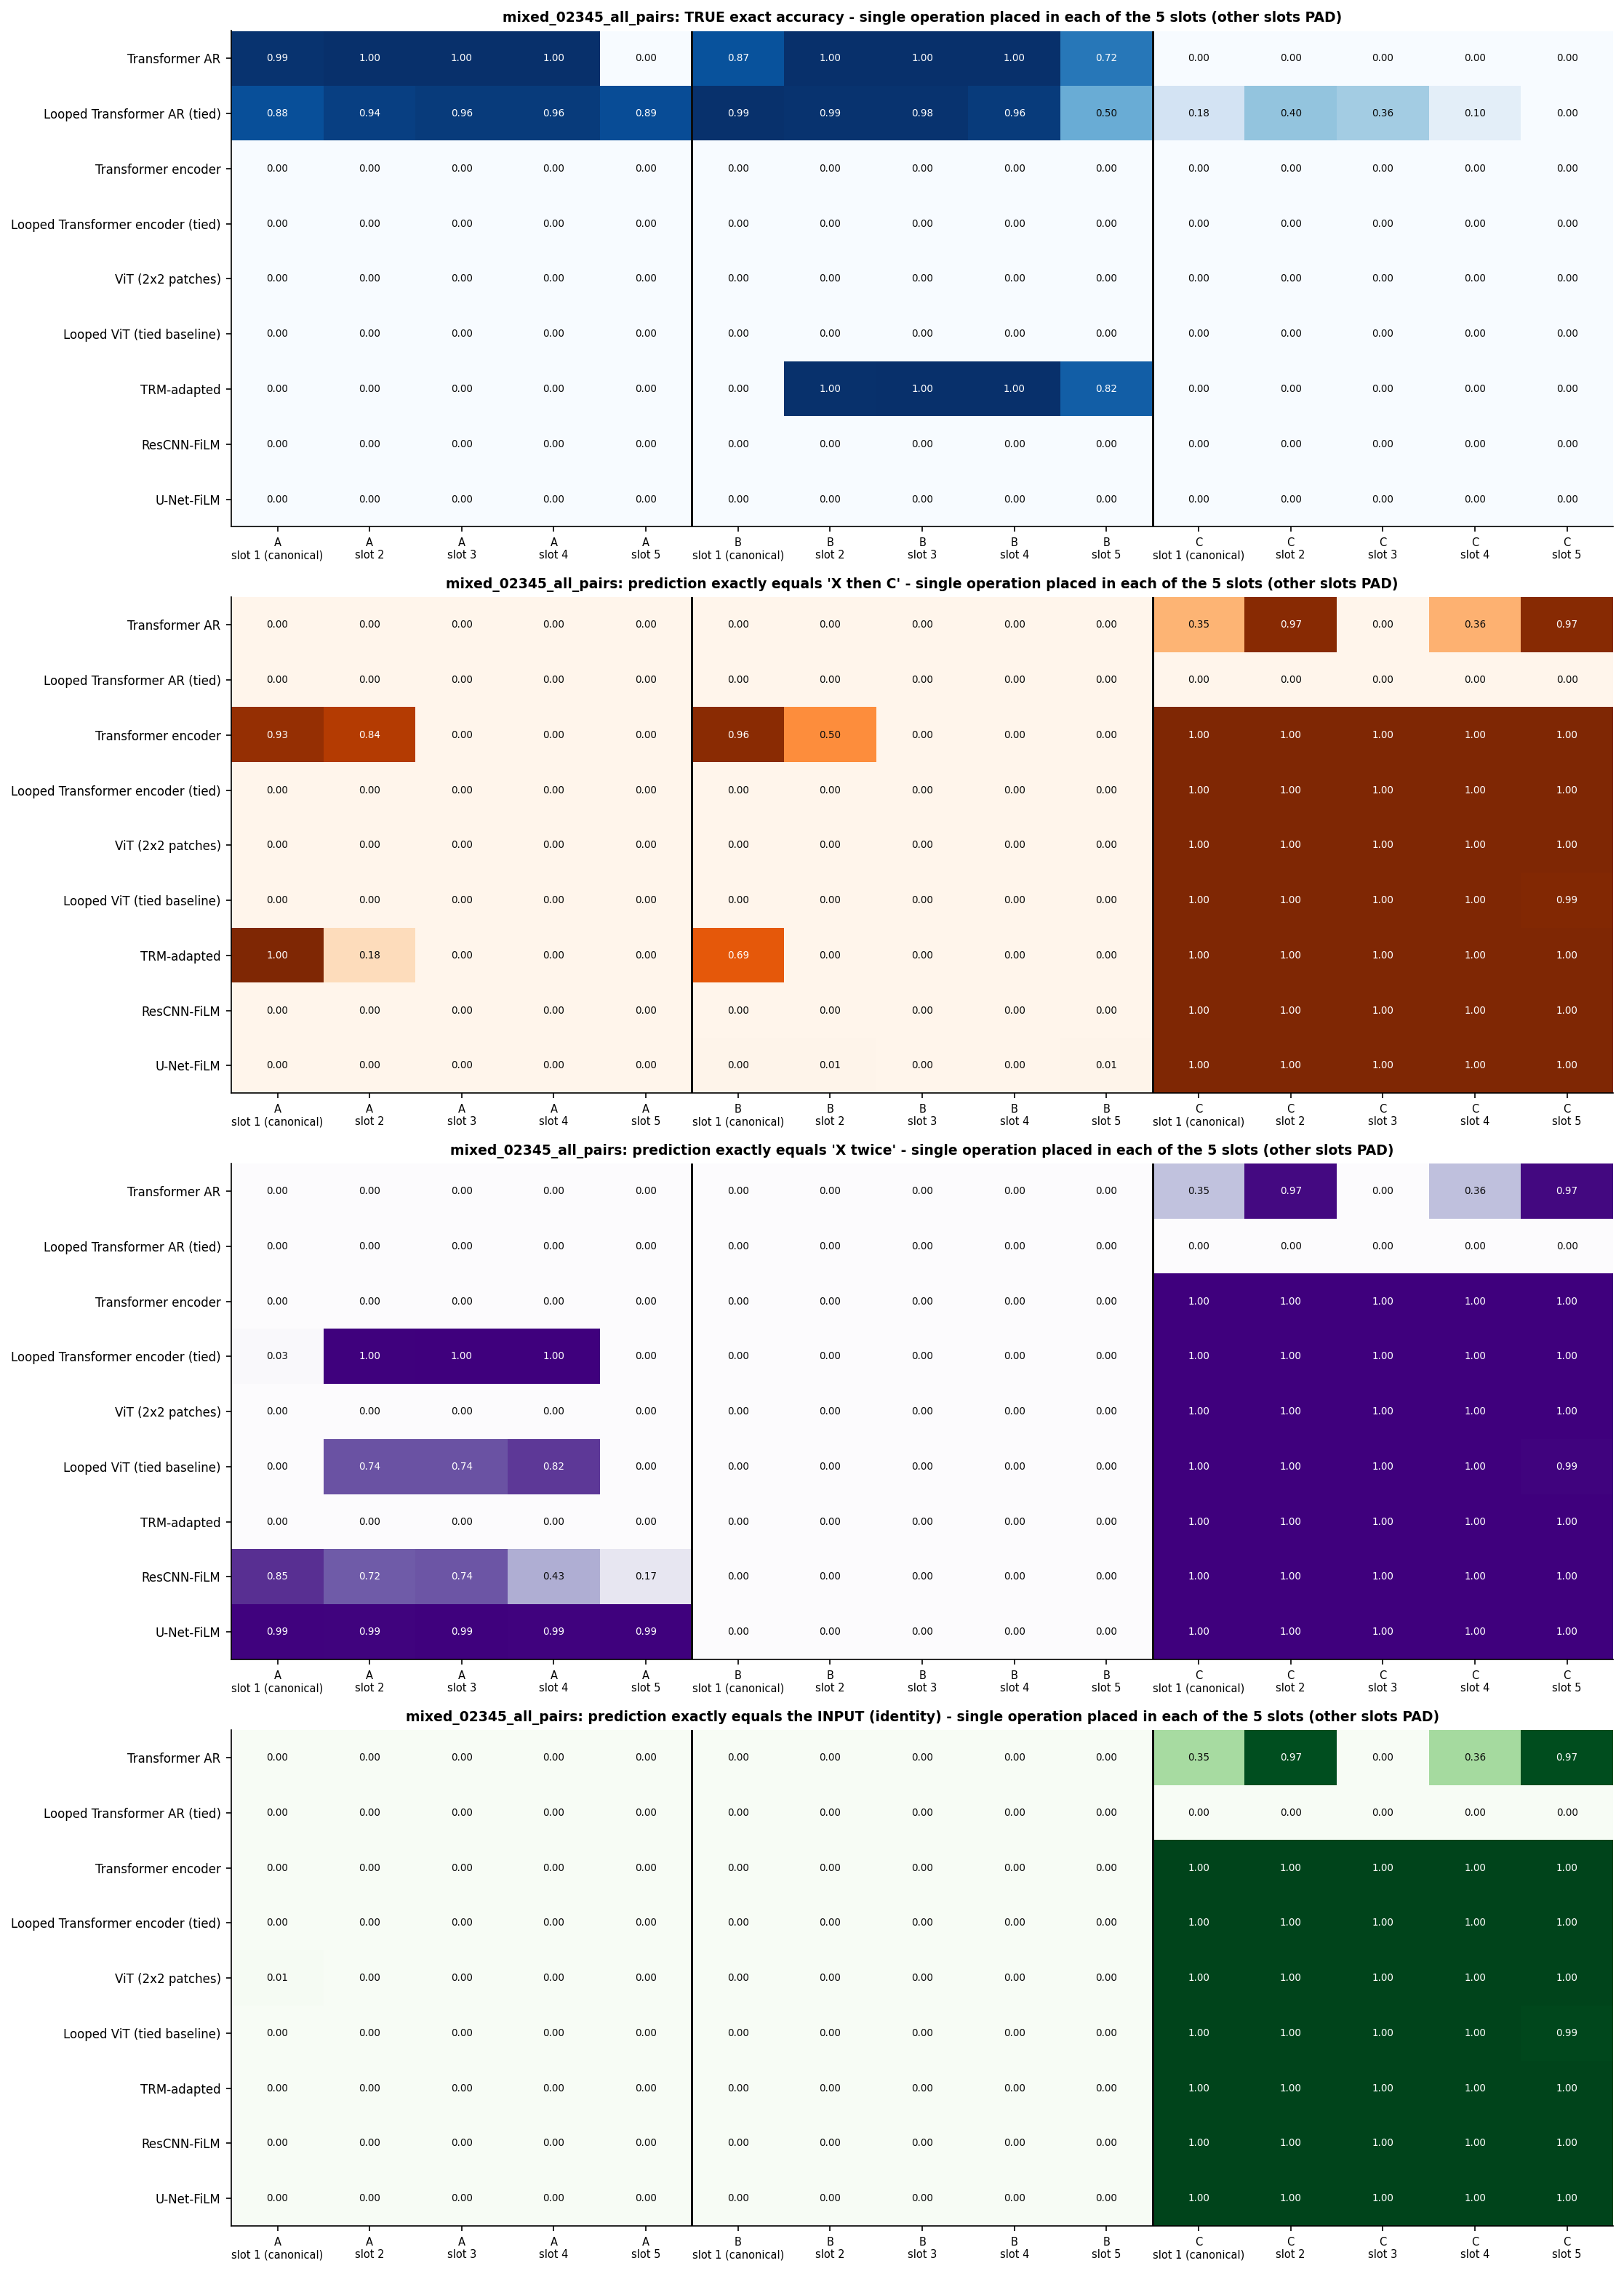

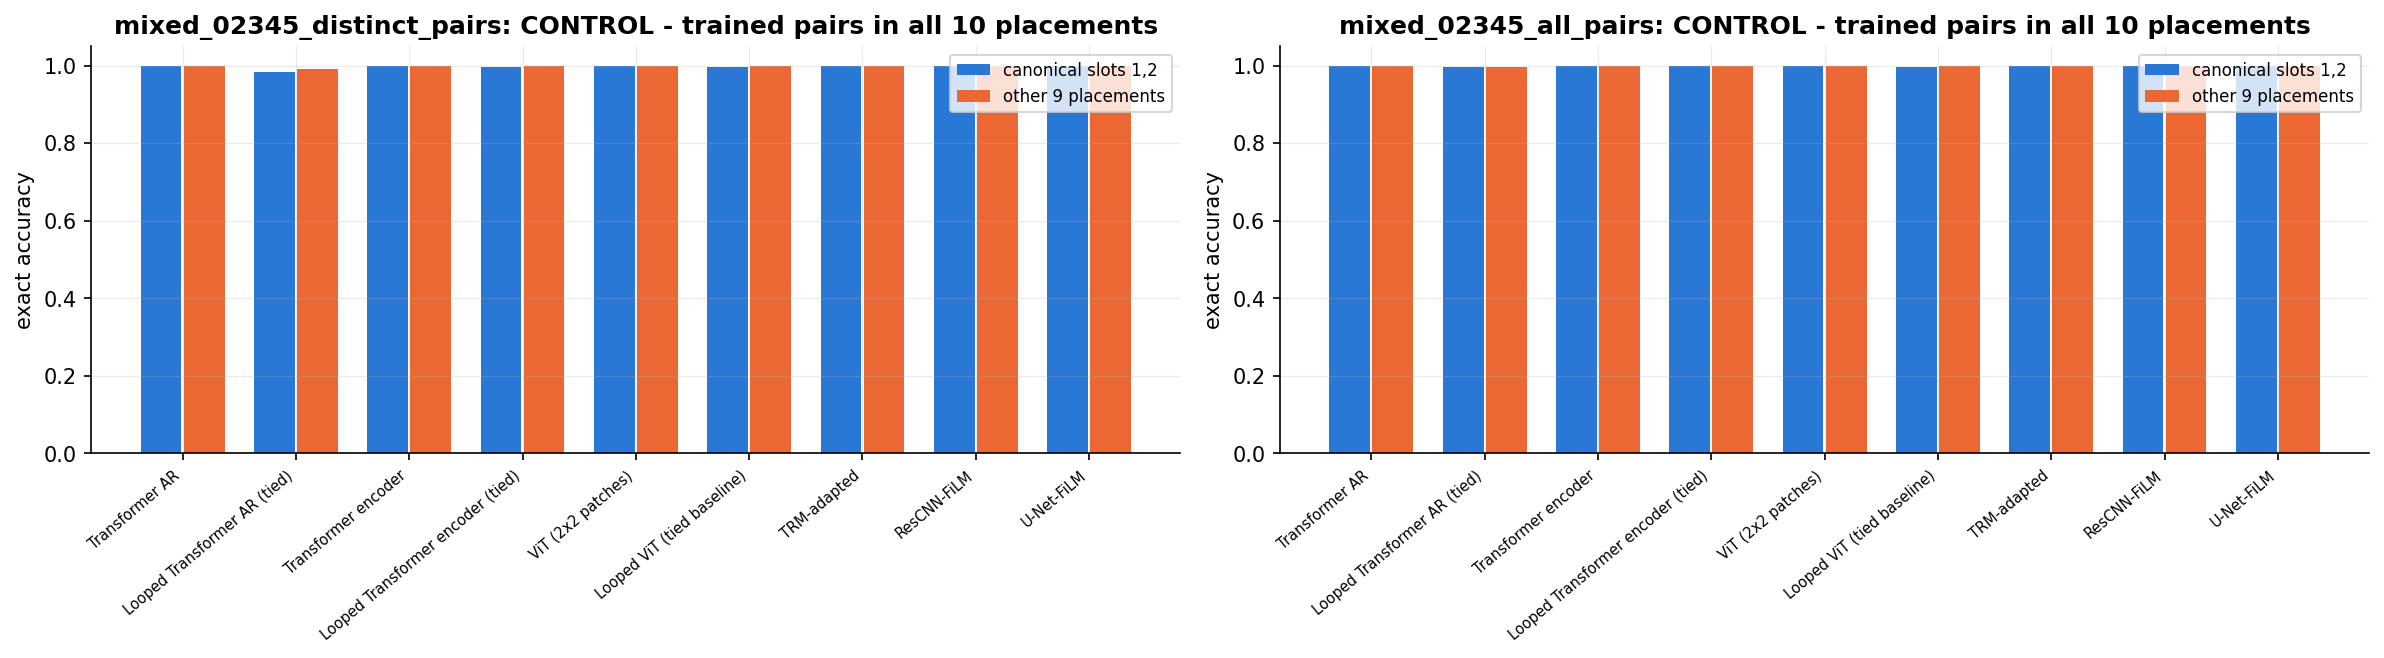

In [3]:
# --- Run the probe (cached per experiment/model; inference only) -------------------------------------------
import pandas as pd
from IPython.display import Image, display
from decompositionality.placement_probe import run_probe, plot_probe
pd.set_option("display.max_rows", 400); pd.set_option("display.width", 250)
res, out = run_probe(MIXED_ROOT, EXPERIMENTS, MODELS, OUTPUT_DIR, N_SINGLE_GRIDS, N_PAIR_GRIDS, DEVICE, DTYPE)
paths = plot_probe(res, out / "figures")
for p in paths:
    if str(p).endswith(".png"):
        display(Image(filename=str(p)))


In [4]:
# --- Numeric tables -----------------------------------------------------------------------------------------
cols = ["experiment", "model", "string", "positions", "exact_correct", "n", "exact_acc", "match: X then C",
        "match: X twice", "match: identity", "any_legal_match_rate", "dominant_wrong_transform", "dominant_wrong_share"]
singles = res[res.kind == "single"][cols]
display(singles.style.format(precision=3).hide(axis="index"))
ctrl = res[res.kind == "pair_control"]
display(ctrl.groupby(["experiment", "model", "canonical_placement"])[["exact_correct", "n"]].sum()
        .assign(exact_acc=lambda d: d.exact_correct / d.n))


experiment,model,string,positions,exact_correct,n,exact_acc,match: X then C,match: X twice,match: identity,any_legal_match_rate,dominant_wrong_transform,dominant_wrong_share
mixed_02345_distinct_pairs,transformer_ar,A,slots 1,0,1000,0.000,0.053,0.000,0.000,0.053,AC,0.053
mixed_02345_distinct_pairs,transformer_ar,A,slots 2,3,1000,0.003,0.000,0.000,0.000,0.003,,0.000
mixed_02345_distinct_pairs,transformer_ar,A,slots 3,955,1000,0.955,0.000,0.000,0.000,0.955,,0.000
mixed_02345_distinct_pairs,transformer_ar,A,slots 4,112,1000,0.112,0.000,0.000,0.000,0.112,,0.000
mixed_02345_distinct_pairs,transformer_ar,A,slots 5,220,1000,0.220,0.000,0.000,0.000,0.220,,0.000
mixed_02345_distinct_pairs,transformer_ar,B,slots 1,994,1000,0.994,0.000,0.000,0.000,0.994,,0.000
mixed_02345_distinct_pairs,transformer_ar,B,slots 2,1000,1000,1.000,0.000,0.000,0.000,1.000,,0.000
mixed_02345_distinct_pairs,transformer_ar,B,slots 3,1000,1000,1.000,0.000,0.000,0.000,1.000,,0.000
mixed_02345_distinct_pairs,transformer_ar,B,slots 4,1000,1000,1.000,0.000,0.000,0.000,1.000,,0.000
mixed_02345_distinct_pairs,transformer_ar,B,slots 5,1000,1000,1.000,0.000,0.000,0.000,1.000,,0.000


exact_correct      n  exact_acc
experiment                 model                      canonical_placement                                 
mixed_02345_all_pairs      looped_transformer_ar      False                        16161  16200   0.997593
                                                      True                          1793   1800   0.996111
                           looped_transformer_encoder False                        16197  16200   0.999815
                                                      True                          1799   1800   0.999444
                           looped_vit                 False                        16189  16200   0.999321
                                                      True                          1796   1800   0.997778
                           rescnn_film                False                        16200  16200   1.000000
                                                      True                          1800   1800   1.000000
                           transformer_ar             False                        16200  16200   1.000000
                                                      True                          1800   1800   1.000000
                           transformer_encoder        False                        16199  16200   0.999938
                                                      True                          1799   1800   0.999444
                           trm                        False                        16200  16200   1.000000
                                                      True                          1800   1800   1.000000
                           unet_film                  False                        16190  16200   0.999383
                                                      True                          1799   1800   0.999444
                           vit                        False                        16200  16200   1.000000
                                                      True                          1799   1800   0.999444
mixed_02345_distinct_pairs looped_transformer_ar      False                        10708  10800   0.991481
                                                      True                          1181   1200   0.984167
                           looped_transformer_encoder False                        10800  10800   1.000000
                                                      True                          1196   1200   0.996667
                           looped_vit                 False                        10795  10800   0.999537
                                                      True                          1197   1200   0.997500
                           rescnn_film                False                        10800  10800   1.000000
                                                      True                          1200   1200   1.000000
                           transformer_ar             False                        10797  10800   0.999722
                                                      True                          1200   1200   1.000000
                           transformer_encoder        False                        10795  10800   0.999537
                                                      True                          1200   1200   1.000000
                           trm                        False                        10800  10800   1.000000
                                                      True                          1200   1200   1.000000
                           unet_film                  False                        10800  10800   1.000000
                                                      True                          1200   1200   1.000000
                           vit                        False                        10799  10800   0.999907
                                                      True                          1199   1200   0.999167

In [5]:
# --- Export -------------------------------------------------------------------------------------------------
import shutil
arch = shutil.make_archive(str(out) + "_export", "zip", root_dir=out, base_dir=".")
print("tables/figures:", out, "| archive:", arch)


tables/figures: /content/drive/MyDrive/decompositionality_results/mixed_length_02345/placement_probe | archive: /content/drive/MyDrive/decompositionality_results/mixed_length_02345/placement_probe_export.zip


Outputs: `<RESULTS_ROOT>/mixed_length_02345/placement_probe/` (per-model `probe_predictions.npz` + `probe_meta.json` with the checkpoint step, `placement_probe_results.csv`, `figures/`).